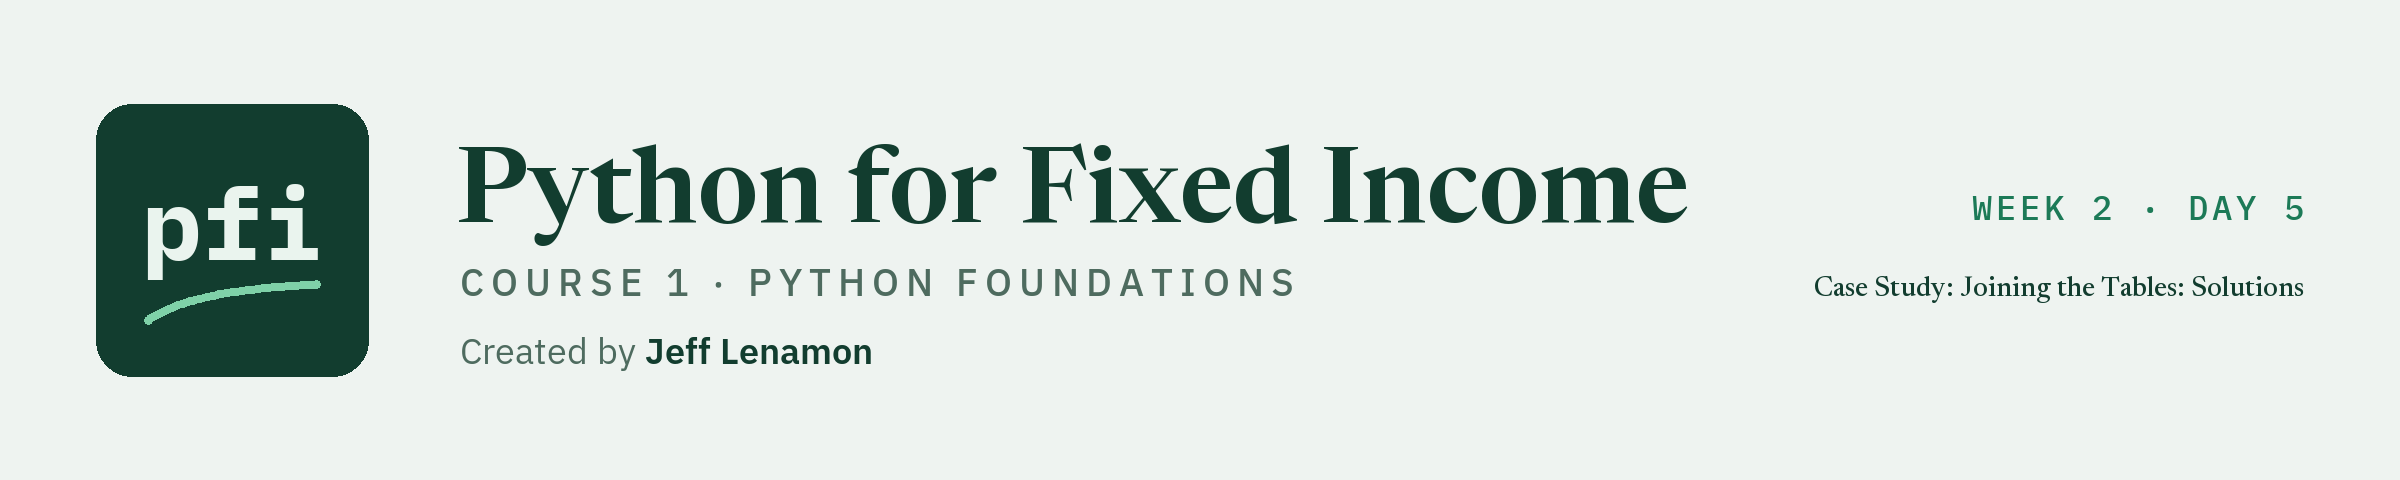

# Case Study: Joining the Tables: Solutions

Week 2, Day 5. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day5/10_case_study_joining_the_tables_solutions.ipynb)

## Exercises

These are the worked answers to the exercises in the teaching notebook; the issuers are invented.
Each answer is followed by the check cell from the teaching notebook.
Run the next two cells first: the first defines `check`; the second loads fresh copies of the files and rebuilds `book`.

In [1]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [2]:
import os

import pandas as pd

# fresh copies of the four files. In Colab they are read from GitHub.
if os.path.exists('../../../data/positions.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
positions = pd.read_csv(data_folder + 'positions.csv')
issuers = pd.read_csv(data_folder + 'issuers.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
benchmark = pd.read_csv(data_folder + 'benchmark.csv')

# the book, rebuilt: two guarded left joins and two new columns
book = pd.merge(positions, issuers, on='ticker', how='left', validate='many_to_one')
book = pd.merge(book, ratings, on='rating', how='left', validate='many_to_one')
book['value'] = book['par_held'] * book['price'] / 100
book['coupon_income'] = book['par_held'] * book['coupon'] / 100
print(book.shape, book['par_held'].sum())

(200, 15) 489000000


### Exercise 1

Q. How many bonds, and how much face, does the book hold in Utilities and Transportation together? Use `isin()`; store the answers in **ex1_bonds** and **ex1_face**.

In [3]:
# the rows of the book in either sector
two_sectors = book[book['sector'].isin(['Utilities', 'Transportation'])]

ex1_bonds = len(two_sectors)
ex1_face = two_sectors['par_held'].sum()

print('Bonds:', ex1_bonds)
print('Face:', ex1_face)

Bonds: 32
Face: 79250000


32 bonds with 79,250,000 of face: the lesson's sector table had 12 in Utilities and 20 in Transportation.

In [4]:
check('Exercise 1 bonds', ex1_bonds, 32)
check('Exercise 1 face', ex1_face, 79250000)

Exercise 1 bonds: correct
Exercise 1 face: correct


### Exercise 2

Q. What is the book's average price, simple and weighted by value? Round each to 2 decimal places and store them in **ex2_simple** and **ex2_weighted**. Is the weighted one higher? Store True or False in **ex2_weighted_higher**.

In [5]:
simple_price = book['price'].mean()

# each price times its value, added up, over the total value
weighted_price = (book['price'] * book['value']).sum() / book['value'].sum()

ex2_simple = round(simple_price, 2)
ex2_weighted = round(weighted_price, 2)
ex2_weighted_higher = weighted_price > simple_price

print('Simple average price:', ex2_simple)
print('Value-weighted average price:', ex2_weighted)
print('Weighted is higher:', ex2_weighted_higher)

Simple average price: 98.83
Value-weighted average price: 99.33
Weighted is higher: True


98.83 simple and 99.33 weighted by value, half a point higher.
The value is face times price, so a higher price earns a larger weight for the same face, which pulls a value-weighted price up.
The lesson's 98.778 was the same average weighted by face.

In [6]:
check('Exercise 2 simple', ex2_simple, 98.83)
check('Exercise 2 weighted', ex2_weighted, 99.33)
check('Exercise 2 weighted higher', ex2_weighted_higher, True)

Exercise 2 simple: correct
Exercise 2 weighted: correct
Exercise 2 weighted higher: correct


### Exercise 3

Q. Which three sectors pay the most coupon income a year, largest first? Store their names as a list in **ex3_top_three**, and the largest one's income in **ex3_top_income**.

In [7]:
# coupon income added up within each sector, largest first
income_by_sector = book.groupby('sector')['coupon_income'].sum()
top_three = income_by_sector.sort_values(ascending=False).head(3)
print(top_three)

# tolist() on the names, iloc[0] for the first income
ex3_top_three = top_three.index.tolist()
ex3_top_income = top_three.iloc[0]

sector
Materials     4205937.5
Financials    3881250.0
Consumer      3545312.5
Name: coupon_income, dtype: float64


Materials, Financials, and Consumer, in that order; Materials pays 4,205,937.5 a year.
They are the three sectors that hold the most value in the lesson, in the same order.

In [8]:
check('Exercise 3 top three', ex3_top_three, ['Materials', 'Financials', 'Consumer'])
check('Exercise 3 top income', ex3_top_income, 4205937.5)

Exercise 3 top three: correct
Exercise 3 top income: correct


### Exercise 4

The benchmark's `accrued` column is accrued interest per 100 of face, one row per `cusip`.

Q. Left-join the book with the benchmark's `cusip` and `accrued` columns. Store the rows in **ex4_rows**, the book's accrued interest in **ex4_accrued**, and its value with accrued in **ex4_full_value**, the last two rounded to 2 decimal places.

In [9]:
# only the key and the one column wanted, so no other benchmark column comes along
with_accrued = pd.merge(book, benchmark[['cusip', 'accrued']], on='cusip', how='left',
                        validate='many_to_one')

# the lesson's check: rows and face, and no gaps in the new column
print('Rows:', book.shape[0], with_accrued.shape[0])
print('Face:', book['par_held'].sum(), with_accrued['par_held'].sum())
print('Missing accrued:', with_accrued['accrued'].isna().sum())

# accrued is per 100 of face, like the price
accrued_dollars = with_accrued['par_held'] * with_accrued['accrued'] / 100

ex4_rows = with_accrued.shape[0]
ex4_accrued = round(accrued_dollars.sum(), 2)
ex4_full_value = round(with_accrued['value'].sum() + accrued_dollars.sum(), 2)

print('Accrued interest:', ex4_accrued)
print('Value with accrued interest:', ex4_full_value)

Rows: 200 200
Face: 489000000 489000000
Missing accrued: 0
Accrued interest: 7794985.0
Value with accrued interest: 490819215.0


200 rows before and after, the same face, and no missing accrued: every CUSIP was found once.
7,794,985 of accrued on top of the 483,024,230 at the clean price gives 490,819,215, Combining Part 1's market value.
Selecting `benchmark[['cusip', 'accrued']]` matters: the whole benchmark would bring `ticker`, `price`, and more a second time, under changed names.

In [10]:
check('Exercise 4 rows', ex4_rows, 200)
check('Exercise 4 accrued', ex4_accrued, 7794985.0)
check('Exercise 4 full value', ex4_full_value, 490819215.0)

Exercise 4 rows: correct
Exercise 4 accrued: correct
Exercise 4 full value: correct


### Exercise 5

Q. Write `join_is_safe(before, after)`, returning True when the two tables have the same number of rows and the same total `par_held`, and False otherwise; replace `return ...` with your code. Then call it on the positions and their outer join with the issuers on `ticker`, and store what it returns in **ex5_outer_safe**.

In [11]:
def join_is_safe(before, after):
    """
    Take the table before a join and the table after it,
    and return True when both have the same number of rows
    and the same total par_held. Return False otherwise.
    """
    # a count of rows and a total of whole dollars are exact, so == is the right test
    same_rows = after.shape[0] == before.shape[0]
    same_face = after['par_held'].sum() == before['par_held'].sum()
    return same_rows and same_face

# the book against the positions it was built from
print('Left joins safe:', join_is_safe(positions, book))

# an outer join keeps the 35 issuers with no position as well
outer = pd.merge(positions, issuers, on='ticker', how='outer')
ex5_outer_safe = join_is_safe(positions, outer)
print('Outer join safe:', ex5_outer_safe, 'rows:', outer.shape[0])

Left joins safe: True
Outer join safe: False rows: 235


True for the book and False for the outer join: its face still sums to 489,000,000, but its 235 rows fail.
`and` is right here, since `same_rows` and `same_face` are each one True or False; `&` is for whole columns.
The function returns its answer, so it fits in an `assert`: `assert join_is_safe(positions, book), 'the join changed the rows or the face'`.

In [12]:
# the first check calls your function on the positions and the book
check('Exercise 5 left joins', join_is_safe(positions, book), True)
check('Exercise 5 outer join', ex5_outer_safe, False)

Exercise 5 left joins: correct
Exercise 5 outer join: correct


### Exercise 6

Q. Build the lesson's two issuer summaries, keep the issuers with four bonds or more, and merge the two. How many are left, which has the highest average coupon, and what is it, to 3 decimal places? Store the answers in **ex6_count**, **ex6_top_issuer**, and **ex6_top_coupon**.

In [13]:
# one row per issuer, with the issuer as an ordinary column
avg_coupon = book.groupby('issuer')[['coupon']].mean().reset_index()
bond_count = book.groupby('issuer')[['cusip']].count().reset_index()
bond_count = bond_count.rename(columns={'cusip': 'bonds'})

# four bonds or more, then the coupons beside them
four_plus = bond_count[bond_count['bonds'] >= 4]
view = four_plus.merge(avg_coupon, on='issuer', how='left')
print(view)

top = view.sort_values('coupon', ascending=False).iloc[0]
ex6_count = len(view)
ex6_top_issuer = top['issuer']
ex6_top_coupon = round(top['coupon'], 3)

                issuer  bonds    coupon
0    Clavoquil Bancorp      4  5.093750
1  Elverone Industrial      4  5.250000
2       Nevulex Health      6  5.395833
3       Pellwick Paper      4  5.312500


Four issuers have four bonds or more, and Nevulex Health, the one with six, has the highest average coupon, 5.396 percent.
Filtering the counts first means the merge keeps only those four.

In [14]:
check('Exercise 6 count', ex6_count, 4)
check('Exercise 6 top issuer', ex6_top_issuer, 'Nevulex Health')
check('Exercise 6 top coupon', ex6_top_coupon, 5.396)

Exercise 6 count: correct
Exercise 6 top issuer: correct
Exercise 6 top coupon: correct


### Exercise 7: AI check

You ask an AI assistant how many bonds the desk holds in Utilities and Transportation.
The code was written for this course in the style of an AI answer, and it had one bug.

Q. What number do you expect, from Exercise 1? Run the code. Does it agree?

Exercise 1's answer is 32; the original code printed 47, with no error.
The bug was the order of the tables: `pd.merge(issuers, positions, ...)` made the issuers the left table, so all 150 were kept, the 35 with no bond among them.
15 of those 35 are in Utilities or Transportation, and `len()` counted them as bonds: 32 plus 15 is 47.
The lesson's row check catches it in one line, since the join has 235 rows, not 200; start from the positions, the table whose rows are the bonds.

In [15]:
# the positions are the left table: one row per bond held
joined = pd.merge(positions, issuers, on='ticker', how='left')
joined = pd.merge(joined, ratings, on='rating', how='left')
print('Rows:', joined.shape[0])

# the rows in the two sectors
two_sectors = joined[joined['sector'].isin(['Utilities', 'Transportation'])]
ex7_bonds = len(two_sectors)

print(f'Bonds in Utilities and Transportation: {ex7_bonds}')

Rows: 200
Bonds in Utilities and Transportation: 32


In [16]:
check('Exercise 7 bonds', ex7_bonds, 32)

Exercise 7 bonds: correct
